In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from pandas.core import frame

In [7]:
df=fetch_california_housing(as_frame=True)
df=df.frame
df.head(10)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611


In [8]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

### Dataset is clean. So we start working with it.

# Regression

In [12]:
mid=df['MedHouseVal'].median() #find median house price
df['PriceCategory']=df['MedHouseVal'].apply(lambda x:1 if x>mid else 0) # high vs low price
df.head(10)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,PriceCategory
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526,1
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585,1
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521,1
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413,1
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422,1
5,4.0368,52.0,4.761658,1.103627,413.0,2.139896,37.85,-122.25,2.697,1
6,3.6591,52.0,4.931907,0.951362,1094.0,2.128405,37.84,-122.25,2.992,1
7,3.1200,52.0,4.797527,1.061824,1157.0,1.788253,37.84,-122.25,2.414,1
8,2.0804,42.0,4.294118,1.117647,1206.0,2.026891,37.84,-122.26,2.267,1
9,3.6912,52.0,4.970588,0.990196,1551.0,2.172269,37.84,-122.25,2.611,1


In [13]:
df.tail(10)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal,PriceCategory
20630,3.5673,11.0,5.932584,1.134831,1257.0,2.824719,39.29,-121.32,1.120,0
20631,3.5179,15.0,6.145833,1.141204,1200.0,2.777778,39.33,-121.40,1.072,0
20632,3.1250,15.0,6.023377,1.080519,1047.0,2.719481,39.26,-121.45,1.156,0
20633,2.5495,27.0,5.445026,1.078534,1082.0,2.832461,39.19,-121.53,0.983,0
20634,3.7125,28.0,6.779070,1.148256,1041.0,3.026163,39.27,-121.56,1.168,0
20635,1.5603,25.0,5.045455,1.133333,845.0,2.560606,39.48,-121.09,0.781,0
20636,2.5568,18.0,6.114035,1.315789,356.0,3.122807,39.49,-121.21,0.771,0
20637,1.7000,17.0,5.205543,1.120092,1007.0,2.325635,39.43,-121.22,0.923,0
20638,1.8672,18.0,5.329513,1.171920,741.0,2.123209,39.43,-121.32,0.847,0
20639,2.3886,16.0,5.254717,1.162264,1387.0,2.616981,39.37,-121.24,0.894,0


In [16]:
x_reg=df.drop(['MedHouseVal', 'PriceCategory'], axis=1)
y_reg=df['MedHouseVal']
x_train_reg,x_test_reg,y_train_reg,y_test_reg=train_test_split(x_reg,y_reg,test_size=0.2,random_state=42)

### Linear Regression

In [18]:
from sklearn.linear_model import LinearRegression

lin=LinearRegression()
lin.fit(x_train_reg,y_train_reg)

y_pred=lin.predict(x_test_reg)
print(f"First 5 predictions: {y_pred[:5]}")
print(f"First 5 labels: {y_test_reg[:5].values}")

First 5 predictions: [0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]
First 5 labels: [0.477   0.458   5.00001 2.186   2.78   ]


#### Evaluation

In [25]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

mae=mean_absolute_error(y_test_reg,y_pred)
mse=mean_squared_error(y_test_reg,y_pred)

print(f"Mean Absolute Error: {mae}")
print(f"Mean Square Error: {mse}")

Mean Absolute Error: 1.571178972868217
Mean Square Error: 3.3257205978725772


# Classification

### Logistic Regression -> for classification

In [19]:
x_cls=df.drop(['MedHouseVal', 'PriceCategory'], axis=1)
y_cls=df['PriceCategory']
x_train_cls,x_test_cls,y_train_cls,y_test_cls=train_test_split(x_cls,y_cls,test_size=0.2,random_state=42)

In [22]:
from sklearn.linear_model import LogisticRegression

log=LogisticRegression()
log.fit(x_train_cls,y_train_cls)

y_pred=log.predict(x_test_cls)
print(f"First 5 predictions: {y_pred[:5]}")
print(f"First 5 labels: {y_test_cls[:5].values}")

First 5 predictions: [0 0 1 1 1]
First 5 labels: [0 0 1 1 1]


/home/rohan/miniconda3/envs/ml_env/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


#### Evaluation

In [26]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix

accuracy=accuracy_score(y_test_cls,y_pred)
accuracy

0.7996608527131783

In [27]:
precision=precision_score(y_test_cls,y_pred)
precision

0.8050847457627118

In [28]:
recall=recall_score(y_test_cls,y_pred)
recall

0.787420770355924

# K-Means Clustering

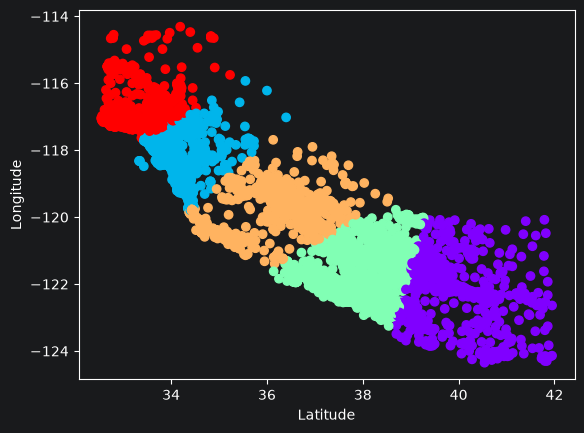

In [24]:
from sklearn.cluster import KMeans

geo=df[['Latitude','Longitude']]

kmeans=KMeans(n_clusters=5, random_state=42, n_init=10)
clusters=kmeans.fit_predict(geo)

plt.scatter(geo['Latitude'],geo['Longitude'], c=clusters, cmap='rainbow')
plt.xlabel("Latitude")
plt.ylabel("Longitude")
plt.show()